# Objective
The objective of this notebook is to test human pose estimation on a small sample of workout videos. We will use a pretrained model to detect body landmarks, visualise the detected joints, and check how reliably the model works on different exercise videos.

# Research Questions
1. Can the model detect body landmarks in workout videos?
2. Which body landmarks are visible and useful for movement analysis?
3. Does landmark detection quality vary across exercise categories?
4. What problems should be addressed before analysing joint angles and repetitions?

In [2]:
from pathlib import Path 
import cv2 
# import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
import pandas as pd

In [5]:
dataset_folder = Path("..") / "data" / "archive(5)"
print(dataset_folder.resolve())
print(dataset_folder.exists())

C:\athlete-performance-injury-risk\data\archive(5)
True


In [ ]:

# File extensions supported by our dataset scan

video_extensions = {".mp4", ".mov", ".avi", ".mkv"}

video_files = []

for file_path in dataset_folder.rglob("*"):
    if file_path.is_file():
        if file_path.suffix.lower() in video_extensions:
            video_files.append(file_path)

# Sort paths (so that the order is repeatable )
video_files = sorted(video_files)

print("Total videos found:", len(video_files))
print("First video:", video_files[0] if video_files else "No videos found")


Total videos found: 652
First video: ..\data\archive(5)\barbell biceps curl\barbell biceps curl_1.mp4


In [12]:
sample_videos = video_files[:5]
print("Length", len(sample_videos))
for video_path in sample_videos:
    print(video_path)


Length 5
..\data\archive(5)\barbell biceps curl\barbell biceps curl_1.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_10.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_11.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_12.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_13.mp4


In [14]:
print("MediaPipe version:", mp.__version__)
print("Pose API available:", hasattr(mp, "solutions"))

MediaPipe version: 1.1.1
Pose API available: False


In [17]:
# download pretrained pose model 
from urllib.request import urlretrieve
model_folder = Path("..") / "models"
model_folder.mkdir(parents=True, exist_ok=True)
model_path = model_folder / "pose_landmarker_lite.task"

model_url = ("https://storage.googleapis.com/mediapipe-models/""pose_landmarker/pose_landmarker_lite/float16/latest/""pose_landmarker_lite.task")

if not model_path.exists():
    print("downloading pose model")
    urlretrieve(model_url,model_path)
else:
    print("pose model already downloaded")

print("Model path:", model_path.resolve())
print("Model downloaded:", model_path.exists())

downloading pose model
Model path: C:\athlete-performance-injury-risk\models\pose_landmarker_lite.task
Model downloaded: True


In [19]:
from mediapipe.tasks import python 
from mediapipe.tasks.python import vision 


base_options = python.BaseOptions(model_asset_path=str(model_path))

options = vision.PoseLandmarkerOptions(base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1)

# Create the pose detector
pose_landmarker = vision.PoseLandmarker.create_from_options(options)
print("Pose model initialized successfully")

Pose model initialized successfully


In [21]:
sample_video = sample_videos[0]
#open the video
cap = cv2.VideoCapture(str(sample_video))

# read its first frame
success, frame = cap.read()

# close th e video file 
cap.release()

print("video", sample_video.name)
print("frame read successfully", success)

if success:
    print("frame height and width", frame.shape[2])

video barbell biceps curl_1.mp4
frame read successfully True
frame height and width 3


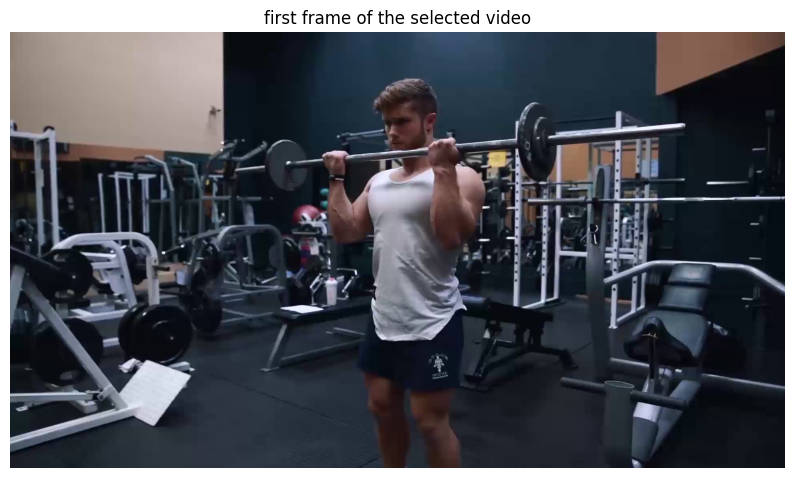

In [22]:
# display th e frame
if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10,6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.title("first frame of the selected video")
    plt.show()
else:
    print("frame not read successfully")


In [24]:
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
# Convert the image into MediaPipe's image format
mp_image = mp.Image(image_format = mp.ImageFormat.SRGB, data = frame_rgb)

# detect body landmarks
result = pose_landmarker.detect(mp_image)

# check the detection results
print("number of detected poses:", len(result.pose_landmarks))

if len(result.pose_landmarks)>0:
    print("number of landmarks detected", len(result.pose_landmarks[0]))
else:
    print("no person is detected inthe frame ")

number of detected poses: 1
number of landmarks detected 33


C:\Users\js731\AppData\Local\Temp\ipykernel_20488\153093382.py:17: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 6))


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

...

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

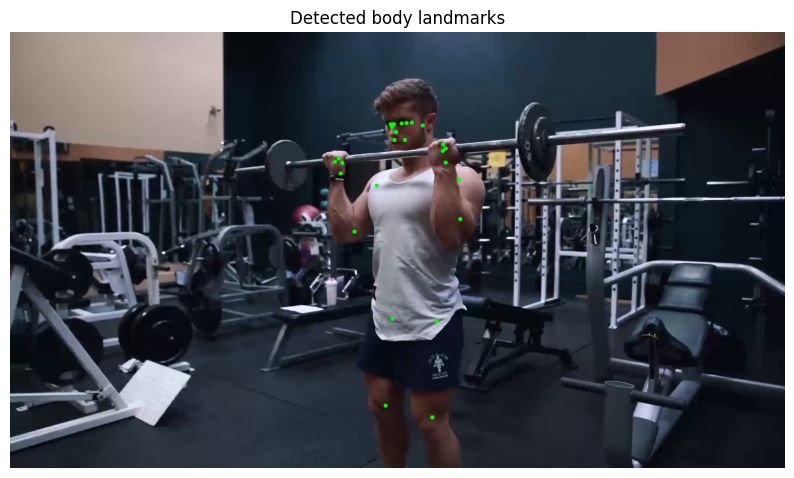

In [26]:
if len(result.pose_landmarks)>0:
    height, width  = frame.shape[:2]
    
    # Make a copy so the original frame remains unchanged
    annotated_frame = frame_rgb.copy()
    
    # Get landmarks for the first detected person
    landmarks = result.pose_landmarks[0]
    for landmark in landmarks:
        # Convert normalised coordinates to pixel coordinates
        x = int(landmark.x*width)
        y = int(landmark.y*height)
        
        # Draw a small circle at each landmark
        cv2.circle(annotated_frame, (x, y), 5, (0, 255, 0), -1)
        
        plt.figure(figsize=(10, 6))
    plt.imshow(annotated_frame)
    plt.axis("off")
    plt.title("Detected body landmarks")
    plt.show()

else:
    print("No landmarks to display.")

In [27]:
#check the landmark visibility 
if len(result.pose_landmarks) > 0:
    landmarks = result.pose_landmarks[0]
    landmark_data = []
    for index, landmark in enumerate(landmarks):
        landmark_data.append({
            "landmark_id": index,
            "x": landmark.x,
            "y": landmark.y,
            "z": landmark.z,
            "visibility": landmark.visibility
        })
    landmark_df = pd.DataFrame(landmark_data)
    display(landmark_df.head(10))
    
    print("Total landmarks:", len(landmark_df))
    print(
        "Average visibility:",
        round(landmark_df["visibility"].mean(), 3)
    )


,landmark_id,x,y,z,visibility
0,0,0.498279,0.229613,-0.210639,0.999779
1,1,0.505566,0.210049,-0.202190,0.999703
2,2,0.511841,0.208941,-0.202359,0.999664
3,3,0.518395,0.207871,-0.202618,0.999581
4,4,0.495593,0.211241,-0.184685,0.999646
5,5,0.493407,0.211272,-0.184842,0.999567
6,6,0.491246,0.211527,-0.184951,0.999493
7,7,0.532480,0.214389,-0.130235,0.999712
8,8,0.492998,0.217201,-0.047231,0.999652
9,9,0.509811,0.247437,-0.181853,0.999673


Total landmarks: 33
Average visibility: 0.925


In [29]:
# Store one video from each exercise category
videos_by_category = {}

for video_path in video_files:
    category = video_path.parent.name
    if category not in videos_by_category:
        videos_by_category[category] = video_path
    
    
# Select up to 5 different exercise categories
pilot_videos = list(videos_by_category.values())[:5]

print("Different exercise categories selected:", len(pilot_videos))

for video_path in pilot_videos:
    print(video_path.parent.name, "->", video_path.name)

Different exercise categories selected: 5
barbell biceps curl -> barbell biceps curl_1.mp4
bench press -> bench press_1.mp4
chest fly machine -> chest fly machine_1.mp4
deadlift -> deadlift_1.mp4
decline bench press -> dbp_1.mp4


In [30]:
pilot_results = []
for video_path in pilot_videos:
    cap = cv2.VideoCapture(str(video_path))
    #read th frame
    success, test_frame = cap.read()
    cap.release()
    # prepare a default result
    detected = False
    landmark_count = 0
    average_visibility = None
    if success:
        #convert BRG to RGB
        test_frame_rgb = cv2.cvtColor(test_frame, cv2.COLOR_BGR2RGB)
        # Convert to MediaPipe image format
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=test_frame_rgb
        )
        # Detect poses
        result = pose_landmarker.detect(mp_image)
        if len(result.pose_landmarks) > 0:
            detected = True
            landmarks = result.pose_landmarks[0]
            landmark_count = len(landmarks)

            average_visibility = sum(
                landmark.visibility for landmark in landmarks
            ) / landmark_count
            
    # Save the result for this video
    pilot_results.append({
        "exercise": video_path.parent.name,
        "video": video_path.name,
        "frame_read": success,
        "pose_detected": detected,
        "landmark_count": landmark_count,
        "average_visibility": average_visibility
    })
    
    
# Display results in a table
pilot_df = pd.DataFrame(pilot_results)
display(pilot_df)

,exercise,video,frame_read,pose_detected,landmark_count,average_visibility
0,barbell biceps curl,barbell biceps curl_1.mp4,True,True,33,0.924679
1,bench press,bench press_1.mp4,True,True,33,0.840786
2,chest fly machine,chest fly machine_1.mp4,True,True,33,0.793724
3,deadlift,deadlift_1.mp4,True,True,33,0.973643
4,decline bench press,dbp_1.mp4,True,True,33,0.722474


In [32]:


# Count how many videos had a person detected
detected_count = pilot_df["pose_detected"].sum()

print("Videos tested:", len(pilot_df))
print("Videos with a detected person:", int(detected_count))

detection_rate = detected_count / len(pilot_df) * 100

print("First-frame detection rate:", round(detection_rate, 1), "%")

Videos tested: 5
Videos with a detected person: 5
First-frame detection rate: 100.0 %


In [33]:
# Create the outputs folder if it does not exist
output_folder = Path("..") / "outputs"
output_folder.mkdir(parents=True, exist_ok=True)

# Save the pilot results
output_path = output_folder / "pose_estimation_pilot.csv"

pilot_df.to_csv(output_path, index=False)

print("Results saved to:", output_path.resolve())

Results saved to: C:\athlete-performance-injury-risk\outputs\pose_estimation_pilot.csv


In [34]:
# Select one video for a more detailed test
test_video = pilot_videos[0]

# Open the video
cap = cv2.VideoCapture(str(test_video))

# Get the total number of frames
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Video:", test_video.name)
print("Total frames:", total_frames)

# Select start, middle, and end frame positions
frame_positions = [
    0,
    total_frames // 2,
    max(0, total_frames - 1)
]

print("Frames selected:", frame_positions)

cap.release()

Video: barbell biceps curl_1.mp4
Total frames: 114
Frames selected: [0, 57, 113]


In [35]:
# Open the selected video
cap = cv2.VideoCapture(str(test_video))

frame_results = []

for frame_number in frame_positions:
    # Move to the selected frame
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

    # Read the frame
    success, test_frame = cap.read()

    if not success:
        print("Could not read frame:", frame_number)
        continue

    # Convert BGR to RGB
    test_frame_rgb = cv2.cvtColor(
        test_frame,
        cv2.COLOR_BGR2RGB
    )

    # Convert to MediaPipe image format
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=test_frame_rgb
    )

    # Detect poses
    result = pose_landmarker.detect(mp_image)

    # Store the results
    detected = len(result.pose_landmarks) > 0
    landmark_count = 0
    average_visibility = None

    if detected:
        landmarks = result.pose_landmarks[0]
        landmark_count = len(landmarks)

        average_visibility = sum(
            landmark.visibility for landmark in landmarks
        ) / landmark_count

    frame_results.append({
        "frame_number": frame_number,
        "pose_detected": detected,
        "landmark_count": landmark_count,
        "average_visibility": average_visibility
    })

cap.release()

# Display the results
frame_df = pd.DataFrame(frame_results)
display(frame_df.round(3))

,frame_number,pose_detected,landmark_count,average_visibility
0,0,True,33,0.925
1,57,True,33,0.814
2,113,True,33,0.754


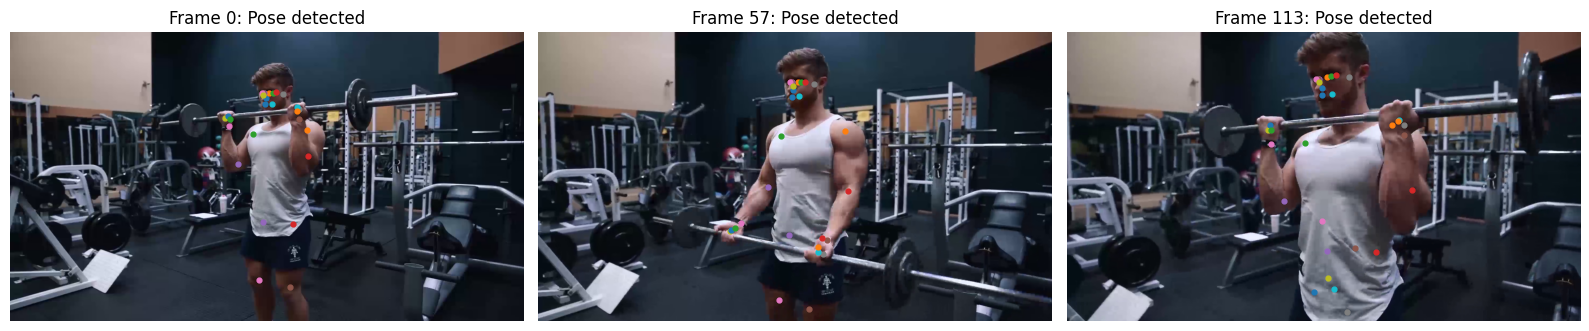

In [36]:
# Open the selected video again
cap = cv2.VideoCapture(str(test_video))

# Create a figure with three image panels
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, frame_number in enumerate(frame_positions):
    # Move to the selected frame
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    success, test_frame = cap.read()

    if not success:
        axes[i].set_title(f"Frame {frame_number}: Read failed")
        axes[i].axis("off")
        continue

    # Convert BGR to RGB
    test_frame_rgb = cv2.cvtColor(
        test_frame,
        cv2.COLOR_BGR2RGB
    )

    # Prepare the image for MediaPipe
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=test_frame_rgb
    )

    # Detect landmarks
    result = pose_landmarker.detect(mp_image)

    # Display the image
    axes[i].imshow(test_frame_rgb)
    axes[i].axis("off")

    if len(result.pose_landmarks) > 0:
        height, width = test_frame.shape[:2]

        for landmark in result.pose_landmarks[0]:
            x = int(landmark.x * width)
            y = int(landmark.y * height)

            if 0 <= x < width and 0 <= y < height:
                axes[i].scatter(x, y, s=12)

        axes[i].set_title(f"Frame {frame_number}: Pose detected")
    else:
        axes[i].set_title(f"Frame {frame_number}: No pose")

cap.release()
plt.tight_layout()
plt.show()

In [37]:
# Count frames where a pose was detected
frames_detected = frame_df["pose_detected"].sum()

# Calculate the detection rate
frame_detection_rate = (
    frames_detected / len(frame_df)
) * 100

# Calculate mean visibility for detected frames
mean_visibility = frame_df.loc[
    frame_df["pose_detected"],
    "average_visibility"
].mean()

print("Frames tested:", len(frame_df))
print("Frames with pose detected:", int(frames_detected))
print("Frame detection rate:", round(frame_detection_rate, 1), "%")
print("Mean visibility:", round(mean_visibility, 3))

Frames tested: 3
Frames with pose detected: 3
Frame detection rate: 100.0 %
Mean visibility: 0.831


In [38]:
# Save the detailed frame-level results
frame_output_path = output_folder / "pose_frame_test.csv"

frame_df.to_csv(frame_output_path, index=False)

print("Frame results saved to:", frame_output_path.resolve())

Frame results saved to: C:\athlete-performance-injury-risk\outputs\pose_frame_test.csv


## Pilot Results and Observations

### 1. Objective

The pilot experiment evaluated whether MediaPipe Pose Landmarker could detect human body landmarks in a small sample of workout videos.

### 2. Results

- Five exercise categories were tested using one frame per video.
- A person was detected in all five sampled frames, giving a first-frame detection rate of 100%.
- The detected person had 33 pose landmarks in the initial test frame.
- Three frames (start, middle, and end) were evaluated from one barbell biceps curl video.
- Pose detection succeeded in all three sampled frames.
- Mean landmark visibility across these three frames was approximately 0.831.

### 3. Observations

The model successfully detected a pose in the sampled frames. However, average landmark visibility decreased from 0.925 in the first frame to 0.754 in the last frame. This variation suggests that landmark visibility should be examined across different stages of an exercise.

### 4. Limitations

- Only five videos were used for the cross-category pilot.
- The multi-frame test covered only one video and three sampled frames.
- Detection rate does not measure anatomical accuracy.
- The pilot did not evaluate joint-angle accuracy, repetition counting, or actual injury outcomes.
- More frames and videos are needed to assess robustness across exercise categories, camera angles, occlusion, and movement stages.

### 5. Conclusion

The initial results support proceeding to a larger pose-landmark extraction experiment. The next stage should evaluate landmark quality across more frames and videos before deriving movement features or potential risk indicators. These results do not establish validated injury prediction performance.